# Direct Sequence Spread Spectrum in Practice: Simulating and Receiving GNSS Signals



## 1. Motivation and GNSS context

GNSS provides positioning, navigation and timing for aviation, maritime navigation, cellular timing, financial timestamping, power systems, autonomous vehicles and robotics. Signal integrity is therefore as important as signal availability.

Common threat categories include:
- **Jamming:** interference raises the noise floor or overwhelms the desired signal.
- **Relaying:** authentic signals are recorded and rebroadcast with delay.
- **Spoofing:** counterfeit signals imitate the structure of authentic navigation signals.

Civilian GNSS signals have historically used publicly documented signal structures and spreading codes. Understanding the signal chain helps explain receiver operation as well as the limits of signal-level defenses.


## 2. DSSS fundamentals

In Direct Sequence Spread Spectrum (DSSS), a low-rate navigation data stream is multiplied by a high-rate pseudorandom (PRN) chipping sequence.

**Notation**

| Symbol | Meaning |
|---|---|
| $$d(t)\in\{-1,+1\}$$ | Navigation data waveform |
| $$c(t)\in\{-1,+1\}$$ | PRN spreading-code waveform |
| $$R_b=1/T_b$$ | Navigation data-bit rate |
| $$R_c=1/T_c$$ | PRN chip rate, with $R_c\gg R_b$ |
| $$A$$ | Signal amplitude |
| $$f_0, \phi$$ | Carrier frequency and phase |

**1. Spreading (baseband)**

$$
\boxed{s(t)=d(t)c(t)}
$$

**2. Modulation onto a carrier**

$$
\boxed{x(t)=A\,d(t)c(t)\cos\!\left(2\pi f_0t+\phi\right)}
$$

**3. Idealized processing gain**

$$
\begin{aligned}
G_p &= \frac{R_c}{R_b} \\
G_p\;(\mathrm{dB}) &= 10\log_{10}\!\left(\frac{R_c}{R_b}\right)
\end{aligned}
$$

For GPS L1 C/A, the nominal chip rate is 1.023 Mcps and the navigation data rate is 50 bps, giving an idealized processing gain of approximately 43.1 dB.

**Why spread spectrum?** Despreading coherently accumulates the wanted code-aligned signal, while uncorrelated interference tends to spread across the correlator output. DSSS also supports code-division multiple access when different users have suitably low cross-correlation codes.


## 3. PRN codes and correlation

A pseudorandom noise (PRN) code is deterministic and repeatable, but has noise-like statistical properties. Useful code families aim for:

- balance between \(+1\) and \(-1\) chips;
- a sharp autocorrelation peak at zero delay;
- low cross-correlation with other codes.

**Normalized discrete correlation**

$$
\boxed{
R_{rc}[\tau]
=
\frac{1}{L}
\sum_{n=0}^{L-1} r[n]\,c[n-\tau]
}
$$

| Symbol | Meaning |
|---|---|
| $$r[n]$$ | Received chip-rate samples |
| $$c[n]$$ | Locally generated PRN sequence |
| $$\tau$$ | Candidate code delay, in samples/chips in this discrete model |
| $$L$$ | Number of samples included in the correlation |

Correlation supports both despreading and code-phase acquisition. A correctly aligned code produces a strong correlation peak; an incorrectly shifted or unrelated code should produce a much smaller value.


## 4. GNSS signal and receiver overview

A simplified GPS L1 C/A signal from satellite $i$ can be represented as

$$
\boxed{
x_i(t)=A_i\,d_i(t)c_i(t)
\cos\!\left(2\pi f_0t+\phi_i\right)
}
$$

Visible satellites share the L1 carrier frequency and are separated by their PRN codes. The antenna receives a sum of satellite signals plus noise.

Before tracking, a receiver performs acquisition to estimate:

- **Code phase** $\tau$: alignment of the local PRN replica.
- **Doppler frequency** $f_d$: frequency shift caused primarily by relative satellite/receiver motion and oscillator error.

**Simplified code-phase/Doppler acquisition metric**

$$
\boxed{
S(\tau,f_d)=
\left|
\frac{1}{N}
\sum_{n=0}^{N-1}
r[n]c[n-\tau]
e^{-j2\pi f_dnT_s}
\right|
}
$$

Here, $r[n]$ is the sampled received signal, $T_s$ is the sampling interval, and $N$ is the coherent integration length. The receiver searches candidate values of $\tau$ and $f_d$, looking for a strong metric peak.

After acquisition and tracking, the receiver forms pseudoranges. A simplified pseudorange model is

$$
\boxed{
\rho_i =
\left\|\mathbf{x}-\mathbf{x}_i\right\|
+c\,\delta t_{\mathrm{receiver}}
+\epsilon_i
}
$$

where $\mathbf{x}$ is receiver position, $\mathbf{x}_i$ is satellite $i$'s position, $c$ is the speed of light, $\delta t_{\mathrm{receiver}}$ is receiver clock bias in seconds, and $\epsilon_i$ groups measurement errors.

At least four satellites are needed to solve for three-dimensional position and receiver clock bias, subject to satellite geometry and measurement quality.


## 5. Hands-On 1 — Build DSSS and receive it

**Learning goals**
1. Generate data bits and a PRN chipping sequence.
2. Spread data using the PRN code.
3. Add simulated additive white Gaussian noise (AWGN).
4. Despread using correlation with the known code.
5. Compare spreading factors and inspect bit errors.
6. Add an unknown chip delay and recover it using a correlation search.



#### 1. Imports and reproducibility

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

#### 2. DSSS transmit/receive function

Function to trainsmit and receive using DSSS.

In [ ]:
def dsss_transmit_receive(chips_per_bit=31, n_bits=8, snr_db=-5, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)

    # Generate data bits (+1/-1)
    data_bits = 2 * rng.integers(0, 2, size=n_bits) - 1
    data_wave = np.repeat(data_bits, chips_per_bit)

    # Generate one PRN period and repeat it once per data bit
    prn_period = chips_per_bit
    prn_code = 2 * rng.integers(0, 2, size=prn_period) - 1
    prn = np.tile(prn_code, n_bits)

    # Spread: multiply data by PRN
    spread_signal = data_wave * prn

    # AWGN channel
    spread_power = np.mean(spread_signal ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = spread_power / snr_linear
    noise = np.sqrt(noise_power) * rng.standard_normal(spread_signal.shape)
    received = spread_signal + noise

    # Despread: correlate each bit interval against the known PRN code
    recovered_bits = np.zeros(n_bits, dtype=int)
    correlation_trace = np.zeros(n_bits)
    for k in range(n_bits):
        start = k * chips_per_bit
        stop = start + chips_per_bit
        corr_val = np.sum(received[start:stop] * prn_code) / chips_per_bit
        correlation_trace[k] = corr_val
        recovered_bits[k] = 1 if corr_val >= 0 else -1

    bit_errors = int(np.sum(recovered_bits != data_bits))

    return {
        "data_bits": data_bits,
        "data_wave": data_wave,
        "prn_code": prn_code,
        "prn": prn,
        "spread_signal": spread_signal,
        "received": received,
        "recovered_bits": recovered_bits,
        "correlation_trace": correlation_trace,
        "bit_errors": bit_errors,
        "chips_per_bit": chips_per_bit,
        "snr_db": snr_db,
    }

#### 3. Run the baseline experiment



In [ ]:
result = dsss_transmit_receive(
    chips_per_bit=31,
    n_bits=8,
    snr_db=-5,
    rng=np.random.default_rng(42)
)

print("Transmitted bits:", result["data_bits"])
print("Recovered bits:  ", result["recovered_bits"])
print(f'Bit errors: {result["bit_errors"]} / {len(result["data_bits"])}')

Transmitted bits: [-1  1  1 -1 -1  1 -1  1]
Recovered bits:   [-1  1  1 -1 -1  1 -1  1]
Bit errors: 0 / 8


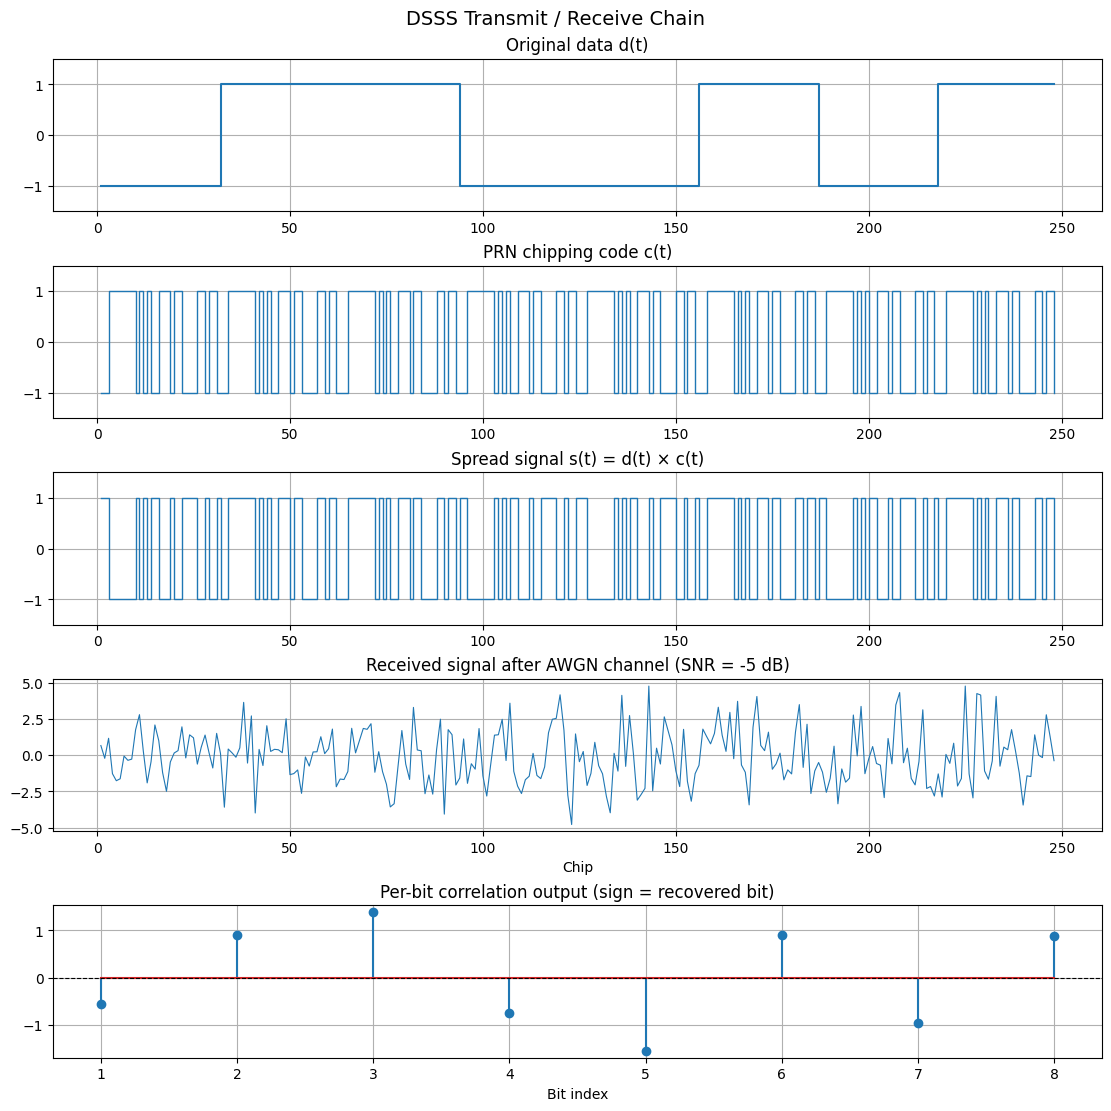

In [ ]:
def plot_dsss_result(result):
    data_wave = result["data_wave"]
    prn = result["prn"]
    spread_signal = result["spread_signal"]
    received = result["received"]
    corr = result["correlation_trace"]
    n_bits = len(result["data_bits"])
    t = np.arange(1, len(data_wave) + 1)

    fig, axes = plt.subplots(5, 1, figsize=(11, 11), constrained_layout=True)

    axes[0].step(t, data_wave, where="post", linewidth=1.5)
    axes[0].set_ylim(-1.5, 1.5)
    axes[0].set_title("Original data d(t)")
    axes[0].grid(True)

    axes[1].step(t, prn, where="post", linewidth=1)
    axes[1].set_ylim(-1.5, 1.5)
    axes[1].set_title("PRN chipping code c(t)")
    axes[1].grid(True)

    axes[2].step(t, spread_signal, where="post", linewidth=1)
    axes[2].set_ylim(-1.5, 1.5)
    axes[2].set_title("Spread signal s(t) = d(t) × c(t)")
    axes[2].grid(True)

    axes[3].plot(t, received, linewidth=0.8)
    axes[3].set_title(f'Received signal after AWGN channel (SNR = {result["snr_db"]} dB)')
    axes[3].set_xlabel("Chip")
    axes[3].grid(True)

    axes[4].stem(np.arange(1, n_bits + 1), corr)
    axes[4].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[4].set_title("Per-bit correlation output (sign = recovered bit)")
    axes[4].set_xlabel("Bit index")
    axes[4].grid(True)

    fig.suptitle("DSSS Transmit / Receive Chain", fontsize=14)
    plt.show()

plot_dsss_result(result)

#### 4. Change the spreading factor

Repeat the experiment with 7 and 63 chips per bit, and compare them with the baseline value of 31.

For a fair comparison, each run starts from the same seed.

In [ ]:
spreading_factors = [7, 31, 63]
results = {}

for sf in spreading_factors:
    results[sf] = dsss_transmit_receive(
        chips_per_bit=sf,
        n_bits=8,
        snr_db=-5,
        rng=np.random.default_rng(42)
    )
    print(
        f"Spreading factor {sf:2d}: "
        f'{results[sf]["bit_errors"]} bit errors / 8'
    )

Spreading factor  7: 1 bit errors / 8
Spreading factor 31: 0 bit errors / 8
Spreading factor 63: 0 bit errors / 8


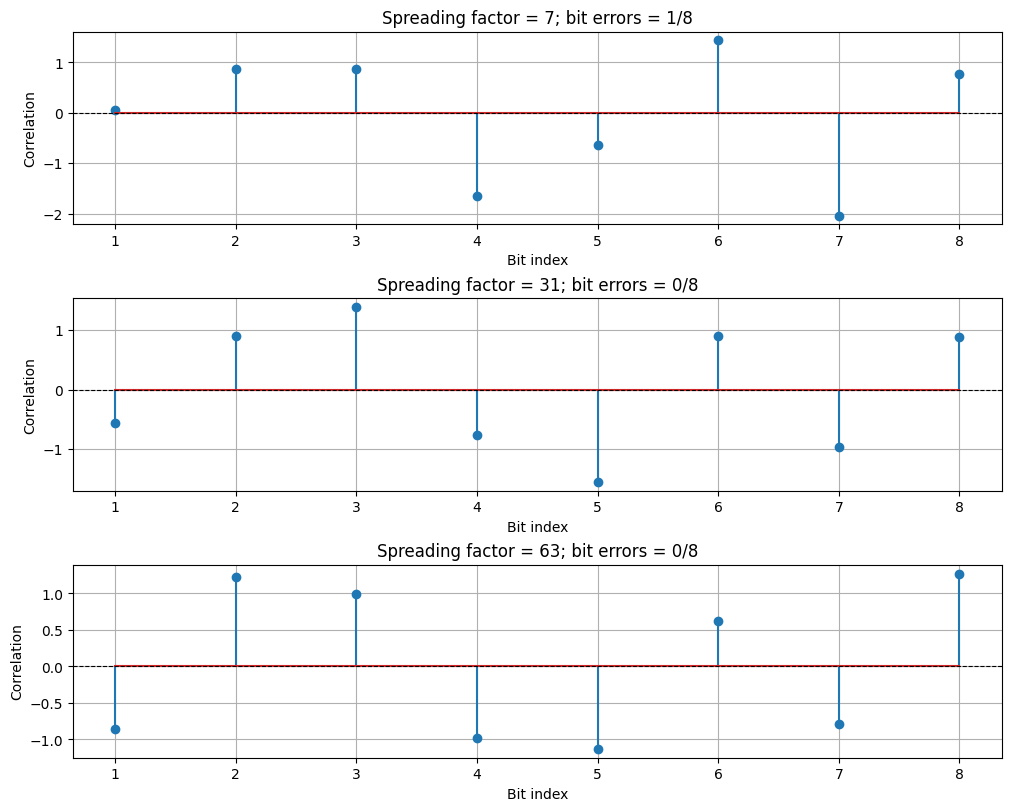

In [ ]:
fig, axes = plt.subplots(len(spreading_factors), 1, figsize=(10, 8), constrained_layout=True)

for ax, sf in zip(axes, spreading_factors):
    r = results[sf]
    ax.stem(np.arange(1, len(r["correlation_trace"]) + 1), r["correlation_trace"])
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f'Spreading factor = {sf}; bit errors = {r["bit_errors"]}/8')
    ax.set_xlabel("Bit index")
    ax.set_ylabel("Correlation")
    ax.grid(True)

plt.show()

#### Key concept

Despreading correlates the received chips with the locally generated PRN sequence. When the code is aligned, the desired data contribution adds coherently, while independent noise tends to average down over the chips in the bit interval.

#### 5. Unknown Delay Acquisition

**Complete the TODO tasks: A, B, C, and D.**



In this part, the received DSSS frame is shifted by an unknown integer number of chips (propagation delay). Estimate the delay by searching candidate code phases and maximizing the absolute correlation with the known PRN code. The absolute value is used because the first navigation data bit may be either +1 or −1.

After estimating the delay, remove the prefix and despread the synchronized frame.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(48)

Generating data

In [ ]:
n_bits = 8
chips_per_bit = 31
snr_db = -5

# Generate data bits (+1/-1)
data_bits = 2 * rng.integers(0, 2, size=n_bits) - 1
data_wave = np.repeat(data_bits, chips_per_bit)

# Generate one PRN code period and repeat it once per bit
prn_period = chips_per_bit
prn_code = 2 * rng.integers(0, 2, size=prn_period) - 1
prn = np.tile(prn_code, n_bits)

# Spread: multiply data by PRN
spread_signal = data_wave * prn

print("Data bits:", data_bits)
print("PRN code length:", len(prn_code))
print("Spread signal length:", len(spread_signal))

Data bits: [-1 -1 -1  1  1  1 -1  1]
PRN code length: 31
Spread signal length: 248


Add AWGN channel and unknown delay

In [ ]:
spread_power = np.mean(spread_signal ** 2)
snr_linear = 10 ** (snr_db / 10)
noise_power = spread_power / snr_linear
noise = np.sqrt(noise_power) * rng.standard_normal(spread_signal.shape)
transmitted = spread_signal + noise

# Apply an unknown integer-chip delay
max_delay = chips_per_bit - 1
unknown_delay = int(rng.integers(0, max_delay + 1))
delayed_signal = np.concatenate([np.zeros(unknown_delay), transmitted])

received = delayed_signal.copy()

print(f"Actual delay: {unknown_delay} chips")
print(f"Received signal length: {len(received)} chips")

Actual delay: 9 chips
Received signal length: 257 chips


Acquisition: one-dimensional correlation search

For each candidate delay, take $N_c$ received chips and correlate them with the known PRN code.

**Correlation magnitude for a candidate delay**

$$
\boxed{
C(\tau)=
\left|
\sum_{i=0}^{N_c-1}
r[\tau+i]\,c[i]
\right|
}
$$

The estimated delay is the candidate with the largest correlation magnitude:

$$
\boxed{
\hat{\tau}
=
\underset{\tau\in\mathcal{T}}{\operatorname{argmax}}
\;C(\tau)
}
$$

where $N_c$ is the number of chips per bit and $τ$ is the set of candidate integer-chip delays tested by this exercise. The absolute value is used because the navigation data bit may be either \(+1\) or \(-1\).


In [ ]:
correlation_search = np.zeros(max_delay + 1)

for delay in range(max_delay + 1):
    # TODO(A): extract chips_per_bit samples beginning at candidate delay
    test_signal = ...

    # TODO(B): correlate against the known PRN code.
    # Absolute value makes acquisition independent of the unknown first-bit sign.
    correlation_search[delay] = ...

# TODO(C): find the candidate delay with the largest correlation magnitude
estimated_delay = ...

print(f"Actual delay:    {unknown_delay} chips")
print(f"Estimated delay: {estimated_delay} chips")
print(f"Acquisition {'SUCCESS' if estimated_delay == unknown_delay else 'DID NOT MATCH'}")

Actual delay:    9 chips
Estimated delay: 9 chips
Acquisition SUCCESS


Remove the estimated delay and despread.

The delayed prefix is removed. We then keep exactly `n_bits * chips_per_bit` chips and perform the usual per-bit correlation.

In [ ]:
# TODO(D): remove estimated delay; discard any samples beyond the data frame
synchronized = ...

recovered_bits = np.zeros(n_bits, dtype=int)
correlation_trace = np.zeros(n_bits)

for k in range(n_bits):
    start = k * chips_per_bit
    stop = start + chips_per_bit
    corr_val = np.sum(synchronized[start:stop] * prn_code) / chips_per_bit
    correlation_trace[k] = corr_val
    recovered_bits[k] = 1 if corr_val >= 0 else -1

num_errors = int(np.sum(recovered_bits != data_bits))

print("Transmitted bits:", data_bits)
print("Recovered bits:  ", recovered_bits)
print(f"Bit errors: {num_errors} / {n_bits}")

Transmitted bits: [-1 -1 -1  1  1  1 -1  1]
Recovered bits:   [-1 -1 -1  1  1  1 -1  1]
Bit errors: 0 / 8


Visualize the transmit, delay, acquisition and receive chain.

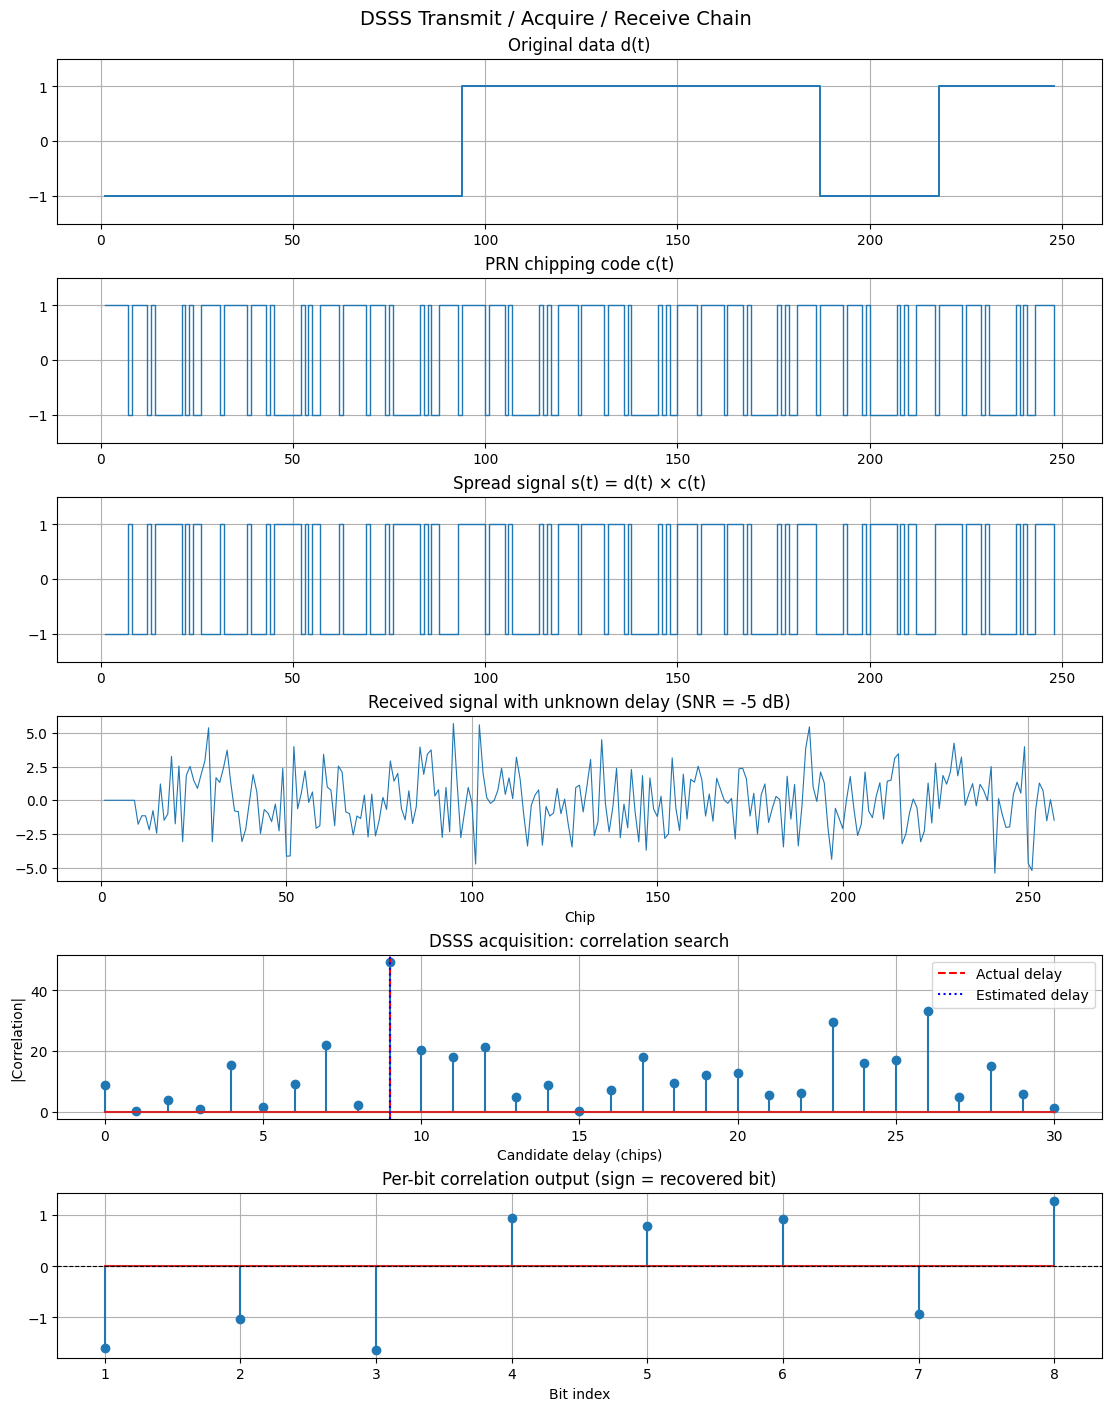

In [ ]:
t_data = np.arange(1, len(data_wave) + 1)
t_received = np.arange(1, len(received) + 1)

fig, axes = plt.subplots(6, 1, figsize=(11, 14), constrained_layout=True)

axes[0].step(t_data, data_wave, where="post", linewidth=1.4)
axes[0].set_ylim(-1.5, 1.5)
axes[0].set_title("Original data d(t)")
axes[0].grid(True)

axes[1].step(t_data, prn, where="post", linewidth=1)
axes[1].set_ylim(-1.5, 1.5)
axes[1].set_title("PRN chipping code c(t)")
axes[1].grid(True)

axes[2].step(t_data, spread_signal, where="post", linewidth=1)
axes[2].set_ylim(-1.5, 1.5)
axes[2].set_title("Spread signal s(t) = d(t) × c(t)")
axes[2].grid(True)

axes[3].plot(t_received, received, linewidth=0.8)
axes[3].set_title(f"Received signal with unknown delay (SNR = {snr_db} dB)")
axes[3].set_xlabel("Chip")
axes[3].grid(True)

candidate_delays = np.arange(max_delay + 1)
axes[4].stem(candidate_delays, correlation_search)
axes[4].axvline(unknown_delay, color="red", linestyle="--", label="Actual delay")
axes[4].axvline(estimated_delay, color="blue", linestyle=":", label="Estimated delay")
axes[4].set_xlabel("Candidate delay (chips)")
axes[4].set_ylabel("|Correlation|")
axes[4].set_title("DSSS acquisition: correlation search")
axes[4].legend()
axes[4].grid(True)

axes[5].stem(np.arange(1, n_bits + 1), correlation_trace)
axes[5].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[5].set_title("Per-bit correlation output (sign = recovered bit)")
axes[5].set_xlabel("Bit index")
axes[5].grid(True)

fig.suptitle("DSSS Transmit / Acquire / Receive Chain", fontsize=14)
plt.show()